Sample Size | Estimated Mean | Estimated Variance
10          25.896          1.882
30          24.624          3.132
100          24.792          3.266
500          25.014          3.844


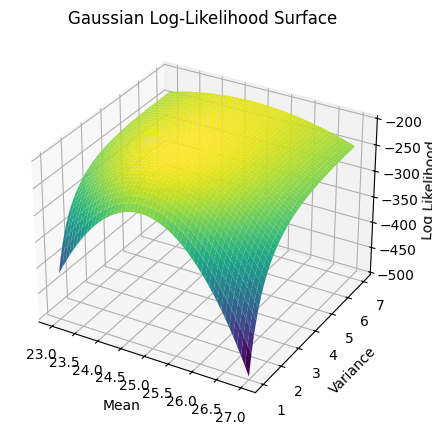


True Mean: 25
Estimated Mean: 25.014
True Variance: 4
Estimated Variance: 3.844


In [11]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Generate Gaussian temperature data
np.random.seed(42)
true_mean = 25
true_var = 4
data = np.random.normal(true_mean, np.sqrt(true_var), 500)

# MLE functions
def estimate_mle(x):
    mean = np.mean(x)
    variance = np.mean((x - mean)**2)
    return mean, variance

# Compare different sample sizes
sizes = [10, 30, 100, 500]

print("Sample Size | Estimated Mean | Estimated Variance")
for n in sizes:
    m, v = estimate_mle(data[:n])
    print(n, "        ", round(m, 3), "        ", round(v, 3))

# Likelihood surface
x = data[:100]
mean_values = np.linspace(23, 27, 50)
var_values = np.linspace(1, 7, 50)
M, V = np.meshgrid(mean_values, var_values)

log_likelihood = np.zeros_like(M)

for i in range(len(var_values)):
    for j in range(len(mean_values)):
        log_likelihood[i, j] = np.sum(
            norm.logpdf(x, loc=M[i, j],
                        scale=np.sqrt(V[i, j]))
        )

# Plot likelihood surface
fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(M, V, log_likelihood, cmap='viridis')
ax.set_xlabel('Mean')
ax.set_ylabel('Variance')
ax.set_zlabel('Log Likelihood')
ax.set_title('Gaussian Log-Likelihood Surface')
plt.show()

# Compare true and estimated parameters
m, v = estimate_mle(data)
print("\nTrue Mean:", true_mean)
print("Estimated Mean:", round(m, 3))
print("True Variance:", true_var)
print("Estimated Variance:", round(v, 3))
